In [1]:
import os
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_absolute_error, max_error, explained_variance_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge

import matplotlib.pyplot as plt

In [2]:
df_dir = 'data/ga_data'

In [3]:
X_train = pd.read_pickle(os.path.join(df_dir, 'X_train.pkl'))
y_train = pd.read_pickle(os.path.join(df_dir, 'y_train.pkl'))

X_test = pd.read_pickle(os.path.join(df_dir, 'X_test.pkl'))
y_test = pd.read_pickle(os.path.join(df_dir, 'y_test.pkl'))

In [5]:
X_train_numeric = X_train.select_dtypes(include=[np.number])
X_test_numeric = X_test.select_dtypes(include=[np.number])

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)
# X_train_scaled[:5], X_test_scaled[:5]

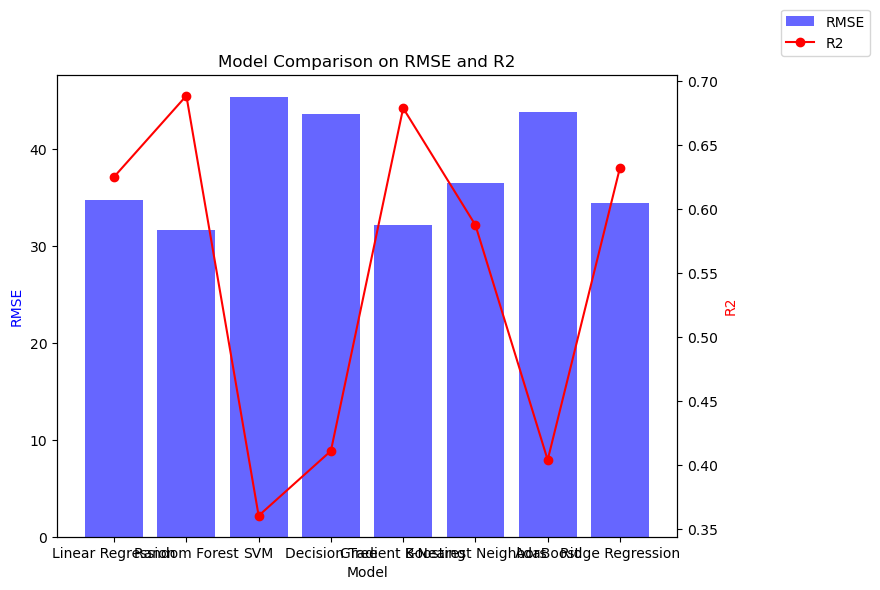

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVM": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "K-Nearest Neighbors": KNeighborsRegressor(),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Ridge Regression": Ridge()
}

contains_zero = (y_test == 0).any()

results = {
    "Model": [],
    "RMSE": [],
    "R2": [],
    "MAE": [],
    "MAPE": [] if not contains_zero else "undefined (contains zero)",
    "Max Error": [],
    "EVS": []
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    mae = mean_absolute_error(y_test, predictions)
    max_error_val = max_error(y_test, predictions)
    evs = explained_variance_score(y_test, predictions)
    mape = (np.abs((y_test - predictions) / y_test).mean() * 100) if not contains_zero else "undefined"
    
    results["Model"].append(name)
    results["RMSE"].append(rmse)
    results["R2"].append(r2)
    
    results["MAE"].append(mae)
    results["MAPE"].append(mape)
    results["Max Error"].append(max_error_val)
    results["EVS"].append(evs)
    
fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()
ax1.bar(range(len(results["Model"])), results["RMSE"], color='b', alpha=0.6, label='RMSE')
ax2.plot(range(len(results["Model"])), results["R2"], color='r', marker='o', label='R2')

ax1.set_xlabel('Model')
ax1.set_ylabel('RMSE', color='b')
ax2.set_ylabel('R2', color='r')
ax1.set_xticks(range(len(results["Model"])))
ax1.set_xticklabels(results["Model"])
ax1.set_title('Model Comparison on RMSE and R2')

fig.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.show()

In [8]:
results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,34.74,0.62,25.89,15.26,185.02,0.63
1,Random Forest,31.67,0.69,21.57,12.48,204.89,0.69
2,SVM,45.36,0.36,35.48,20.26,185.37,0.40
3,Decision Tree,43.53,0.41,27.56,15.89,336.88,0.41
4,Gradient Boosting,32.16,0.68,22.42,13.02,209.59,0.68
5,K-Nearest Neighbors,36.44,0.59,25.68,15.00,185.37,0.59
6,AdaBoost,43.79,0.40,35.94,22.51,298.90,0.42
7,Ridge Regression,34.41,0.63,26.20,15.29,196.79,0.63


In [9]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_features': ['auto', 'sqrt', 'log2'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

gb_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_model = RandomForestRegressor(random_state=42)
# gb_model = GradientBoostingRegressor(random_state=42)

rf_grid_search = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)
# gb_grid_search = GridSearchCV(estimator=gb_model, param_grid=gb_param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)

rf_grid_search.fit(X_train_scaled, y_train)
# gb_grid_search.fit(X_train_scaled, y_train)

rf_best_params = rf_grid_search.best_params_
# gb_best_params = gb_grid_search.best_params_

rf_best_params

Fitting 3 folds for each of 324 candidates, totalling 972 fits


C:\Users\14464\anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
324 fits failed out of a total of 972.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
211 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\14464\anaconda3\lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\14464\anaconda3\lib\site-packages\sklearn\base.py", line 1382, in wrapper
    estimator._validate_params()
  File "C:\Users\14464\anaconda3\lib\site-packages\sklearn\base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "C:\Users\14464\anaconda3\lib\site-packag

{'max_depth': 30,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'n_estimators': 300}

In [10]:
gb_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
# rf_model = RandomForestRegressor(random_state=42)
gb_model = GradientBoostingRegressor(random_state=42)

# rf_grid_search = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)
gb_grid_search = GridSearchCV(estimator=gb_model, param_grid=gb_param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)

# rf_grid_search.fit(X_train_scaled, y_train)
gb_grid_search.fit(X_train_scaled, y_train)

# rf_best_params = rf_grid_search.best_params_
gb_best_params = gb_grid_search.best_params_

gb_best_params

Fitting 3 folds for each of 243 candidates, totalling 729 fits


{'learning_rate': 0.1,
 'max_depth': 5,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'n_estimators': 300}

In [11]:
models.update({
    "Random Forest OP": RandomForestRegressor(random_state=42, max_depth= 30, max_features= 'sqrt',
  min_samples_leaf= 1,
  min_samples_split=5,
  n_estimators= 300),
    "Gradient Boosting OP": GradientBoostingRegressor(random_state=42,learning_rate= 0.1,
  max_depth= 5,
  min_samples_leaf= 4,
  min_samples_split= 2,
  n_estimators= 300),
})

for name, model in models.items():
    if name not in results["Model"]:  
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, predictions)

        mae = mean_absolute_error(y_test, predictions)
        max_error_val = max_error(y_test, predictions)
        evs = explained_variance_score(y_test, predictions)
        mape = (np.abs((y_test - predictions) / y_test).mean() * 100) if not contains_zero else "undefined"

        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)

        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,34.74,0.62,25.89,15.26,185.02,0.63
1,Random Forest,31.67,0.69,21.57,12.48,204.89,0.69
2,SVM,45.36,0.36,35.48,20.26,185.37,0.40
3,Decision Tree,43.53,0.41,27.56,15.89,336.88,0.41
4,Gradient Boosting,32.16,0.68,22.42,13.02,209.59,0.68
5,K-Nearest Neighbors,36.44,0.59,25.68,15.00,185.37,0.59
6,AdaBoost,43.79,0.40,35.94,22.51,298.90,0.42
7,Ridge Regression,34.41,0.63,26.20,15.29,196.79,0.63
8,Random Forest OP,31.32,0.70,21.97,12.80,187.96,0.70
9,Gradient Boosting OP,31.02,0.70,21.03,12.05,199.37,0.70


In [13]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

rf_params = {
    'max_depth': 30,
    'max_features': 'sqrt',
    'min_samples_leaf': 1,
    'min_samples_split': 5,
    'n_estimators': 300
}

rf_model = RandomForestRegressor(**rf_params)
rf_model.fit(X_train_scaled, y_train)

importances = rf_model.feature_importances_

threshold = np.mean(importances)

important_indices = np.where(importances > threshold)[0]
X_train_important = X_train_scaled[:, important_indices]
X_test_important = X_test_scaled[:, important_indices]

lasso_cv = LassoCV(cv=5)
lasso_cv.fit(X_train_important, y_train)

lasso_mask = lasso_cv.coef_ != 0
selected_features = X_train.columns[important_indices][lasso_mask]

selected_features

C:\Users\14464\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 459.1160667538643, tolerance: 455.2115608943834
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\14464\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 621.3447267012671, tolerance: 455.2115608943834
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\14464\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 774.2497459808365, tolerance: 455.2115608943834
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\14464\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: Co

Index(['original_shape2D_Elongation', 'original_shape2D_MinorAxisLength',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_firstorder_RootMeanSquared', 'original_firstorder_Variance',
       'original_glrlm_GrayLevelNonUniformity',
       'original_glrlm_GrayLevelNonUniformityNormalized',
       'original_glrlm_GrayLevelVariance',
       'original_glrlm_LongRunLowGrayLevelEmphasis',
       'original_glrlm_LowGrayLevelRunEmphasis',
       'original_glrlm_RunLengthNonUniformity',
       'original_glrlm_ShortRunEmphasis',
       'original_glrlm_ShortRunHighGrayLevelEmphasis',
       'original_glszm_GrayLevelNonUniformity',
       'original_glszm_GrayLevelNonUniformityNormalized',
       'original_glszm_LargeAreaLowGrayLevelEmphasis',
       'original_glszm_LowGrayLevelZoneEmphasis',
       'original_glszm_SizeZoneNonUniformity',
       'original_glszm_SmallAreaEmphasis',
       'original_glszm_SmallAreaHighGrayLevelEmphasis'],
      dtype='object')

In [14]:
X_train_selected = X_train_scaled[:, important_indices]
X_test_selected = X_test_scaled[:, important_indices]

X_train_final = X_train_selected[:, lasso_mask]
X_test_final = X_test_selected[:, lasso_mask]

rf_model_selected = RandomForestRegressor(**rf_params)

In [15]:
models.update({
    "Random Forest lasso": rf_model_selected
})

for name, model in models.items():
    if name not in results["Model"]:  
        model.fit(X_train_final, y_train)
        predictions = model.predict(X_test_final)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, predictions)

        mae = mean_absolute_error(y_test, predictions)
        max_error_val = max_error(y_test, predictions)
        evs = explained_variance_score(y_test, predictions)
        mape = (np.abs((y_test - predictions) / y_test).mean() * 100) if not contains_zero else "undefined"

        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)

        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,34.74,0.62,25.89,15.26,185.02,0.63
1,Random Forest,31.67,0.69,21.57,12.48,204.89,0.69
2,SVM,45.36,0.36,35.48,20.26,185.37,0.40
3,Decision Tree,43.53,0.41,27.56,15.89,336.88,0.41
4,Gradient Boosting,32.16,0.68,22.42,13.02,209.59,0.68
5,K-Nearest Neighbors,36.44,0.59,25.68,15.00,185.37,0.59
6,AdaBoost,43.79,0.40,35.94,22.51,298.90,0.42
7,Ridge Regression,34.41,0.63,26.20,15.29,196.79,0.63
8,Random Forest OP,31.32,0.70,21.97,12.80,187.96,0.70
9,Gradient Boosting OP,31.02,0.70,21.03,12.05,199.37,0.70


In [16]:
from sklearn.feature_selection import RFECV

rf_model_for_rfe = RandomForestRegressor(**rf_params)

rfe = RFECV(estimator=rf_model_for_rfe, step=1, cv=5, scoring='neg_mean_squared_error', min_features_to_select=1, verbose=0)

rfe.fit(X_train_scaled, y_train)

# selected_features_rfe = X_train.columns[rfe.support_]
# selected_features_rfe, rfe.ranking_

IndexError: boolean index did not match indexed array along dimension 0; dimension is 96 but corresponding boolean dimension is 95

In [17]:
selected_features_rfe = X_train_numeric.columns[rfe.support_]
selected_features_rfe, rfe.ranking_

(Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
        'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
        'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
        'original_shape2D_PerimeterSurfaceRatio',
        'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
        'original_firstorder_10Percentile', 'original_firstorder_90Percentile',
        'original_firstorder_Energy', 'original_firstorder_Kurtosis',
        'original_firstorder_Maximum',
        'original_firstorder_MeanAbsoluteDeviation', 'original_firstorder_Mean',
        'original_firstorder_Range', 'original_firstorder_RootMeanSquared',
        'original_firstorder_Skewness', 'original_firstorder_TotalEnergy',
        'original_firstorder_Variance', 'original_glcm_Correlation',
        'original_glrlm_GrayLevelNonUniformity',
        'original_glrlm_GrayLevelNonUniformityNormalized',
        'original_glrlm_GrayLevelVariance',
        'or

In [20]:
rfe.cv_results_

{'mean_test_score': array([-2788.60486239, -1529.06369451, -1313.36144228, -1300.06611042,
        -1209.41163583, -1178.75077768, -1148.6521019 , -1148.54990791,
        -1144.38743443, -1143.44503294, -1133.64885508, -1114.07617064,
        -1105.23136336, -1103.02010562, -1083.58076458, -1083.76550118,
        -1075.54930514, -1077.75901743, -1070.623457  , -1067.98800419,
        -1069.46165112, -1072.31264304, -1064.30435979, -1059.19219884,
        -1051.73336843, -1057.77990309, -1057.14726592, -1064.81956877,
        -1062.95139411, -1057.2986804 , -1055.5289843 , -1059.91560005,
        -1062.106973  , -1058.9363856 , -1048.65893382, -1055.25528354,
        -1054.93181939, -1053.45532329, -1050.81026701, -1055.56914311,
        -1049.61551796, -1048.16111602, -1049.6380078 , -1045.29631594,
        -1047.14465673, -1047.46758389, -1046.42411587, -1033.34059612,
        -1042.43334318, -1030.64533508, -1044.63517457, -1040.250904  ,
        -1035.0727224 , -1034.55509287, -1031

In [18]:
X_train_selected = X_train_scaled[:, rfe.support_]
X_test_selected = X_test_scaled[:, rfe.support_]

rf_model_retrained = RandomForestRegressor(**rf_params)
rf_model_retrained.fit(X_train_selected, y_train)

MSE: 974.3452786339132
RMSE: 31.214504299026007
MAE: 21.78284831342951
R²: 0.6971798996937614


In [19]:
models.update({
    "Random Forest RFE": rf_model_retrained
})

for name, model in models.items():
    if name not in results["Model"]:  
        model.fit(X_train_final, y_train)
        predictions = model.predict(X_test_final)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, predictions)

        mae = mean_absolute_error(y_test, predictions)
        max_error_val = max_error(y_test, predictions)
        evs = explained_variance_score(y_test, predictions)
        mape = (np.abs((y_test - predictions) / y_test).mean() * 100) if not contains_zero else "undefined"

        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)

        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,34.74,0.62,25.89,15.26,185.02,0.63
1,Random Forest,31.67,0.69,21.57,12.48,204.89,0.69
2,SVM,45.36,0.36,35.48,20.26,185.37,0.40
3,Decision Tree,43.53,0.41,27.56,15.89,336.88,0.41
4,Gradient Boosting,32.16,0.68,22.42,13.02,209.59,0.68
5,K-Nearest Neighbors,36.44,0.59,25.68,15.00,185.37,0.59
6,AdaBoost,43.79,0.40,35.94,22.51,298.90,0.42
7,Ridge Regression,34.41,0.63,26.20,15.29,196.79,0.63
8,Random Forest OP,31.32,0.70,21.97,12.80,187.96,0.70
9,Gradient Boosting OP,31.02,0.70,21.03,12.05,199.37,0.70
